# Model Evaluation
This notebook evaluates clustering and recommendation models separately. Recommendation relevance is synthetic and must not be interpreted as real roommate satisfaction.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
sys.path.insert(0,str(PROJECT_DIR))
from src.evaluation import synthetic_compatibility_ground_truth,recommendation_metrics,catalog_coverage,recommendation_diversity,precision_at_k,recall_at_k,ndcg_at_k
from src.recommendation import knn_recommend,cosine_recommend,weighted_recommend

cleaned=pd.read_csv(PROJECT_DIR/'data/dormmatch_cleaned.csv')
raw=pd.read_csv(PROJECT_DIR/'data/dormmatch_raw.csv')
scaled=pd.read_csv(PROJECT_DIR/'data/dormmatch_scaled_features.csv')
clustering_metrics=pd.read_csv(PROJECT_DIR/'models/clustering_metrics.csv')
assignments=pd.read_csv(PROJECT_DIR/'models/cluster_assignments.csv')
raw_profile=raw[['student_id','guest_frequency','music_frequency']].drop_duplicates('student_id',keep='first')
raw_profile['guest_frequency']=raw_profile['guest_frequency'].astype('string').str.strip().str.lower()
raw_profile['music_frequency']=raw_profile['music_frequency'].astype('string').str.strip().str.lower()
candidates=cleaned.merge(raw_profile,on='student_id',how='left',validate='one_to_one').merge(assignments,on='student_id',how='left',validate='one_to_one')
print('Evaluation rows:',len(candidates))

Evaluation rows: 2000


## Clustering evaluation
These are the actual metrics generated in Notebook 05. The weak silhouette score and multiple balanced-looking cluster sizes should be reported honestly.

In [2]:
clustering_metrics

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,25887.284897,0.182672,2.011865,477.599182
1,3,24402.539437,0.153569,2.533204,313.954922
2,4,23319.786445,0.129720,2.335262,249.803558
3,5,22343.564221,0.082000,2.757027,217.231509
4,6,21858.535136,0.074166,2.797268,186.401520
5,7,21437.421475,0.067055,2.878876,164.831574
6,8,21058.410391,0.065267,2.857553,148.876627
7,9,20733.641666,0.060764,2.959862,136.139454
8,10,20438.868892,0.059928,2.874664,125.885361


In [4]:
# Guest compatibility is a stable textual field, normalized for the synthetic rule.
working=candidates.copy()
working['guest_numeric']=working['guest_frequency'].map({'rarely':1,'sometimes':2,'often':3,'very often':4}).fillna(2)
working['wake_time']=pd.to_numeric(working['wake_time'],errors='coerce')

def circular_gap(a,b):
    d=abs(float(a)-float(b))%24
    return min(d,24-d)

n=len(working)
ground=np.zeros((n,n),dtype=float)
for i in range(n):
    if i%500==0: print('ground truth row',i)
    a=working.iloc[i]
    for j in range(i+1,n):
        b=working.iloc[j]
        sleep_gap=(circular_gap(a.sleep_time,b.sleep_time)+circular_gap(a.wake_time,b.wake_time))/2
        vals=[1-min(sleep_gap/12,1),
              1-abs(a.study_hours-b.study_hours)/18,
              1-abs(a.cleanliness_level-b.cleanliness_level)/4,
              1-abs(a.noise_tolerance-b.noise_tolerance)/4,
              1-abs(a.social_activity-b.social_activity)/4,
              1-abs(a.guest_numeric-b.guest_numeric)/3]
        score=float(np.clip(np.mean(vals),0,1))
        ground[i,j]=ground[j,i]=score
relevant={i:set(np.where(ground[i]>=0.72)[0].tolist())-{i} for i in range(n)}
print('Relevant pair threshold: 0.72')

ground truth row 0


ground truth row 500


ground truth row 1000


ground truth row 1500


Relevant pair threshold: 0.72


## Recommendation comparisons
Precision@5 and Recall@5 use the synthetic relevant sets. NDCG@5 uses binary pair relevance. Diversity is measured by the number of lifestyle clusters represented by recommendations. Catalog coverage is the fraction of the 2,000-student catalog appearing at least once.

In [5]:
X=scaled.to_numpy()
K=5
recommendations={}
for i in range(n):
    knn_ids,_=knn_recommend(X,top_k=K,query_index=i)
    recommendations.setdefault('KNN',{})[i]=[int(v) for v in knn_ids]

    cosine_ids,_=cosine_recommend(X,top_k=K,query_index=i)
    recommendations.setdefault('Cosine',{})[i]=[int(v) for v in cosine_ids]

# Weighted compatibility is calculated in a vector-free way to retain feature explanations.
from src.recommendation import weighted_compatibility
recommendations.setdefault('Weighted',{})
for i in range(n):
    q=working.iloc[i]
    scored=[]
    for j in range(n):
        if i==j: continue
        b=working.iloc[j]
        score=weighted_compatibility(q,b)['overall']
        scored.append((j,score))
    scored.sort(key=lambda x:(-x[1],x[0]))
    recommendations['Weighted'][i]=[j for j,_ in scored[:K]]
print('Recommendations generated for',n,'students')

/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extma

/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extma

/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extma

/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extma

/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extma

/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extma

... (4 outputs left out)

/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extma

/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extma

/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ananyaa/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extma

Recommendations generated for 2000 students


In [6]:
rows=[]
cluster_map=dict(zip(assignments['student_id'],assignments['cluster']))
for method,method_recs in recommendations.items():
    relevant_ids={i:{j for j in relevant if j!=i} for i,relevant in relevant.items()}
    per=[]
    for i,recs in method_recs.items():
        rel=relevant_ids[i]
        relevance={j:1 for j in rel}
        p=precision_at_k(recs,rel,K)
        r=recall_at_k(recs,rel,K)
        nd=ndcg_at_k(recs,relevance,K)
        per.append((p,r,nd))
    ordered=list(method_recs.values())
    unique_clusters=[]
    for rec_indices in ordered:
        rec_ids=candidates.iloc[rec_indices]['student_id'].tolist()
        unique_clusters.append(len(set(cluster_map.get(s,-1) for s in rec_ids))/K)
    recommended_catalog=set(v for recs in method_recs.values() for v in recs)
    rows.append({'Method':method,'Precision@5':np.mean([x[0] for x in per]),'Recall@5':np.mean([x[1] for x in per]),'NDCG@5':np.mean([x[2] for x in per]),'Diversity':np.mean(unique_clusters),'Catalog coverage':len(recommended_catalog)/n})
comparison=pd.DataFrame(rows)
comparison

,Method,Precision@5,Recall@5,NDCG@5,Diversity,Catalog coverage
0,KNN,0.9954,0.003959,0.995561,0.2165,0.9390
1,Cosine,0.9921,0.003947,0.992746,0.2139,0.9585
2,Weighted,1.0000,0.003981,1.000000,0.2369,0.9725


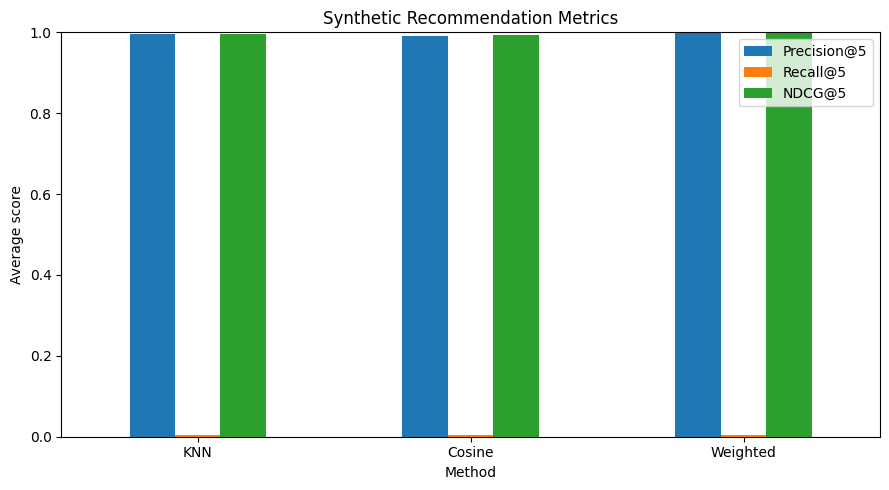

Saved models/recommendation_evaluation.csv


In [7]:
comparison.to_csv(PROJECT_DIR/'models/recommendation_evaluation.csv',index=False)
comparison.plot(x='Method',y=['Precision@5','Recall@5','NDCG@5'],kind='bar',figsize=(9,5),ylim=(0,1),title='Synthetic Recommendation Metrics')
plt.ylabel('Average score')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print('Saved models/recommendation_evaluation.csv')